# Prototype: repairs email triage

> **Practice case study, synthetic data.** The 120 emails in `data/synthetic_repair_emails.csv` were written for this exercise. They contain no real tenant data.

**Purpose:** test whether option C from the [options appraisal](../02-options-appraisal.md) is technically realistic before spending money on a pilot. Specifically:

1. How many emergencies do simple **keyword rules** catch on their own?
2. How accurately can a small open AI model suggest the **trade** and **priority**?
3. Do **rules + AI together** catch every emergency (success measure M1)?

**Approach:** turn each email into a numeric representation with a small open model from Hugging Face (`sentence-transformers/all-MiniLM-L6-v2`), then train a simple classifier on top. With only 120 emails, results use 5-fold cross-validation: every email is predicted by a model that never saw it.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
emails = pd.read_csv(ROOT / "data" / "synthetic_repair_emails.csv")
print(f"{len(emails)} synthetic emails")
emails.groupby(["trade", "priority"]).size().unstack(fill_value=0)

120 synthetic emails


priority,emergency,routine,urgent
trade,,,
carpentry,4,10,6
damp_mould,1,12,7
electrical,6,8,6
heating,5,7,8
plumbing,5,10,5
roofing,3,11,6


## 1. Keyword rules on their own

The rules represent what a team could build without AI (option B). The keyword list would be agreed with the Head of Building Safety (open question Q3).

In [2]:
EMERGENCY_PATTERNS = [
    r"\bgas\b", r"carbon monoxide", r"\bspark", r"burning smell", r"\bsmoke\b", r"exposed wires?",
    r"\bmelted\b", r"no (?:electricity|power)", r"burst pipe", r"sewage", r"\bflood", r"pouring through",
    r"no water", r"collapsed?", r"locked (?:inside|in)", r"can'?t get out", r"break-?in", r"kicked in",
    r"oxygen", r"newborn", r"hole above", r"smashed",
]
rules_re = re.compile("|".join(EMERGENCY_PATTERNS), re.IGNORECASE)
emails["rules_flag"] = emails["text"].str.contains(rules_re)

is_emergency = emails["priority"].eq("emergency")
def summarise(flag, name):
    caught = (flag & is_emergency).sum()
    false_alarms = (flag & ~is_emergency).sum()
    return {"approach": name, "emergencies caught": f"{caught} of {is_emergency.sum()}",
            "recall": round(caught / is_emergency.sum(), 2), "false alarms": int(false_alarms)}

pd.DataFrame([summarise(emails["rules_flag"], "Keyword rules only")])

,approach,emergencies caught,recall,false alarms
0,Keyword rules only,20 of 24,0.83,3


In [3]:
emails.loc[is_emergency & ~emails["rules_flag"], ["email_id", "text"]]

,email_id,text
12,E013,Water coming through the light fitting in the ...
47,E048,There's a funny smell near the boiler and I fe...
68,E069,Plaster on the ceiling is bulging and wet and ...
115,E116,Roof is leaking onto the electrics in the loft.


The rules miss emergencies described in everyday words, such as water coming through a light fitting or "a funny smell near the boiler". This is why rules alone (option B) score lower on safety.

## 2. AI suggestions: trade and priority

In [4]:
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
X = model.encode(emails["text"].tolist(), normalize_embeddings=True, show_progress_bar=False)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = LogisticRegression(max_iter=2000, C=10)

emails["ai_trade"] = cross_val_predict(clf, X, emails["trade"], cv=cv)
priority_proba = cross_val_predict(clf, X, emails["priority"], cv=cv, method="predict_proba")
priority_classes = sorted(emails["priority"].unique())
emails["ai_priority"] = np.array(priority_classes)[priority_proba.argmax(axis=1)]
emails["ai_emergency_prob"] = priority_proba[:, priority_classes.index("emergency")]

trade_acc = accuracy_score(emails["trade"], emails["ai_trade"])
prio_acc = accuracy_score(emails["priority"], emails["ai_priority"])
both = ((emails["trade"] == emails["ai_trade"]) & (emails["priority"] == emails["ai_priority"])).mean()
print(f"Trade accuracy:    {trade_acc:.0%}")
print(f"Priority accuracy: {prio_acc:.0%}")
print(f"Both correct (M5): {both:.0%}")

Trade accuracy:    84%
Priority accuracy: 44%
Both correct (M5): 37%


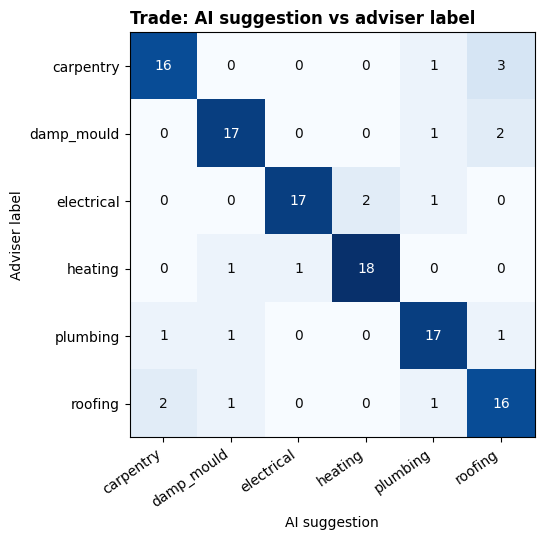

In [5]:
labels = sorted(emails["trade"].unique())
cm = confusion_matrix(emails["trade"], emails["ai_trade"], labels=labels)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
ax.set_xlabel("AI suggestion"); ax.set_ylabel("Adviser label")
ax.set_title("Trade: AI suggestion vs adviser label", loc="left", fontweight="bold")
fig.tight_layout()
(ROOT / "outputs").mkdir(exist_ok=True)
fig.savefig(ROOT / "outputs" / "trade_confusion_matrix.png", dpi=160, facecolor="white")

## 3. Rules + AI together

Safety requirement BR-02: an email is flagged if the rules **or** the AI think it may be an emergency. For the AI, a low threshold is used (flag if the probability of "emergency" is 25% or more), because a false alarm costs an adviser a minute while a missed emergency could cost much more.

In [6]:
THRESHOLD = 0.25
emails["ai_flag"] = emails["ai_emergency_prob"] >= THRESHOLD
emails["combined_flag"] = emails["rules_flag"] | emails["ai_flag"]

results = pd.DataFrame([
    summarise(emails["rules_flag"], "Keyword rules only (option B)"),
    summarise(emails["ai_flag"], f"AI only (threshold {THRESHOLD})"),
    summarise(emails["combined_flag"], "Rules OR AI (option C)"),
])
results

,approach,emergencies caught,recall,false alarms
0,Keyword rules only (option B),20 of 24,0.83,3
1,AI only (threshold 0.25),10 of 24,0.42,16
2,Rules OR AI (option C),21 of 24,0.88,17


In [7]:
missed = emails[is_emergency & ~emails["combined_flag"]]
print(f"Emergencies missed by rules + AI: {len(missed)}")
missed[["email_id", "text", "ai_emergency_prob"]]

Emergencies missed by rules + AI: 3


,email_id,text,ai_emergency_prob
12,E013,Water coming through the light fitting in the ...,0.153909
68,E069,Plaster on the ceiling is bulging and wet and ...,0.009889
115,E116,Roof is leaking onto the electrics in the loft.,0.222300


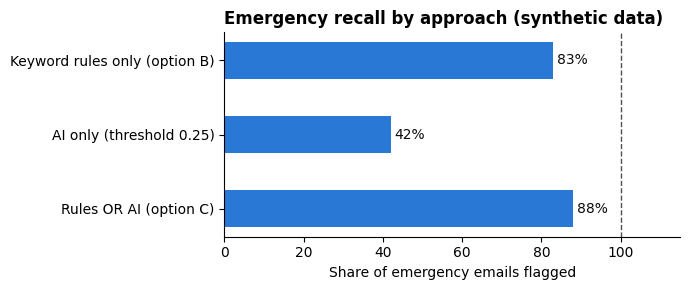

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results["approach"][::-1], results["recall"][::-1] * 100, color="#2a78d6", height=0.5)
for y, v in enumerate(results["recall"][::-1] * 100):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", color="#0b0b0b")
ax.axvline(100, color="#52514e", ls="--", lw=1)
ax.set_xlim(0, 115)
ax.set_xlabel("Share of emergency emails flagged")
ax.set_title("Emergency recall by approach (synthetic data)", loc="left", fontweight="bold")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(ROOT / "outputs" / "emergency_recall.png", dpi=160, facecolor="white")

## 4. What this shows, and what it doesn't

**Results on this synthetic set** (5-fold cross-validation):

| Measure | Result |
|---|---|
| Trade suggested correctly | 84% |
| Priority suggested correctly | 44% |
| Both correct (success measure M5, target 85%) | 37% |
| Emergencies flagged: keyword rules only | 20 of 24 (83%) |
| Emergencies flagged: AI only | 10 of 24 (42%) |
| Emergencies flagged: rules **or** AI | 21 of 24 (88%) |

**What this tells us:**
- **Suggesting the trade works well**, even with a small free model and only 120 examples. This is where most of the adviser time saving would come from.
- **Suggesting the priority does not work yet.** Urgency depends on context (who lives there, how bad it is), not just on the topic, and 120 examples aren't enough to learn that. The AI on its own catches fewer than half of the emergencies.
- **Rules and AI together still missed 3 emergencies.** Two involve water near electrics and one a ceiling that might collapse, so the keyword list needs those hazard types. (They aren't added here: tuning the rules to the same emails used for testing would overstate the result.)
- **Success measure M1 (100% of emergencies flagged) is not met.** This supports the design choices in the assessment: an adviser reviews every email, and the pilot starts in shadow mode.

**What it doesn't show:**
- **Real-world accuracy.** These emails are short, clear, and written and labelled by one person. Real emails are longer and messier.
- **Fairness** by language, email length or writing style (risk R-04).

**Next steps for the pilot:**
1. Test on 12 months of historical emails (within the DPIA), which gives far more examples of each priority.
2. Compare this approach with a larger instruction-following model for priority, using the same cross-validation.
3. Review the emergency keyword list with the Head of Building Safety, using the missed cases from the historical test.